# Lecture 8 — Class Exercise
## Choropleth Maps

> **Push to:** `week08/lecture08_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


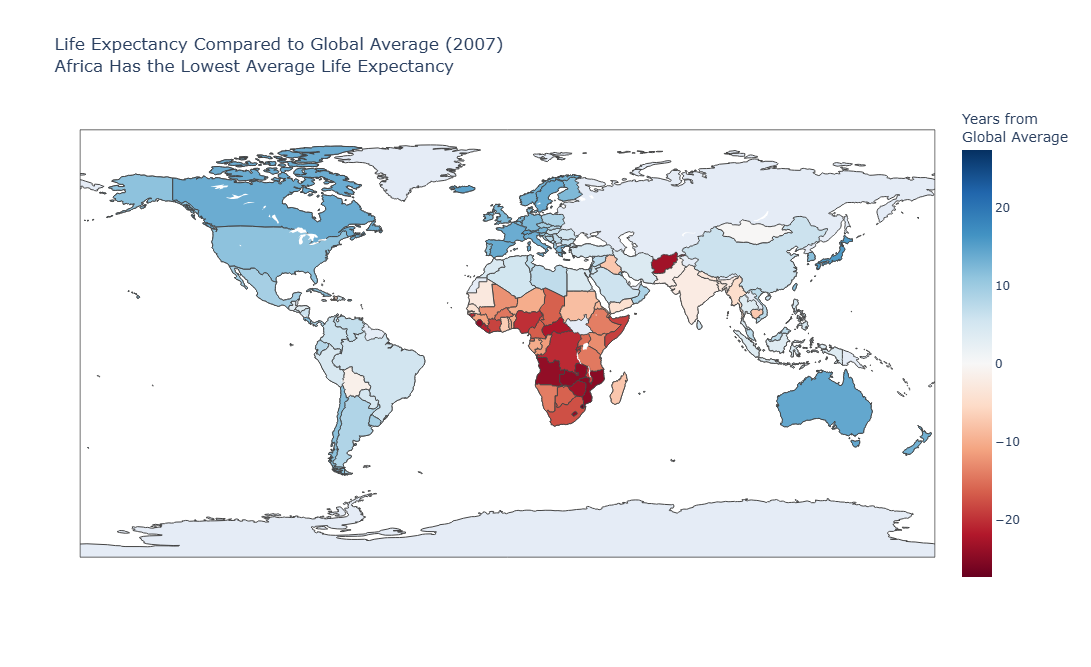

In [3]:
# Task 1
# YOUR CODE HERE
import plotly.express as px

gm = px.data.gapminder()
gm_2007 = gm[gm['year'] == 2007].copy()

global_mean = gm_2007['lifeExp'].mean()

gm_2007['deviation'] = gm_2007['lifeExp'] - global_mean

region_mean = gm_2007.groupby('continent')['lifeExp'].mean()
lowest_region = region_mean.idxmin()
fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    color='deviation',
    hover_name='country',
    hover_data={
        'lifeExp': ':.2f',
        'deviation': ':.2f',
        'iso_alpha': False
    },
    color_continuous_scale='RdBu',
    color_continuous_midpoint=0,
    title=f'Life Expectancy Compared to Global Average (2007)<br>'
          f'{lowest_region} Has the Lowest Average Life Expectancy'
)
fig.update_layout(
    width=1100,
    height=650,
    coloraxis_colorbar_title='Years from<br>Global Average'
)
fig.show()

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *(https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json?utm_source=chatgpt.com)*

**Chart type chosen** :px.choropleth

Reason: It allows us to create a geographical map using the GeoJSON file and compare police officer rates across US states.

**Colour scale chosen** : Sequential (Blues) 

Reason: The police officer rate is a continuous, non-negative variable. Darker blue represents a higher rate, while lighter blue represents a lower rate.
*Your answer here*


{'name': 'Alabama', 'density': 94.65}


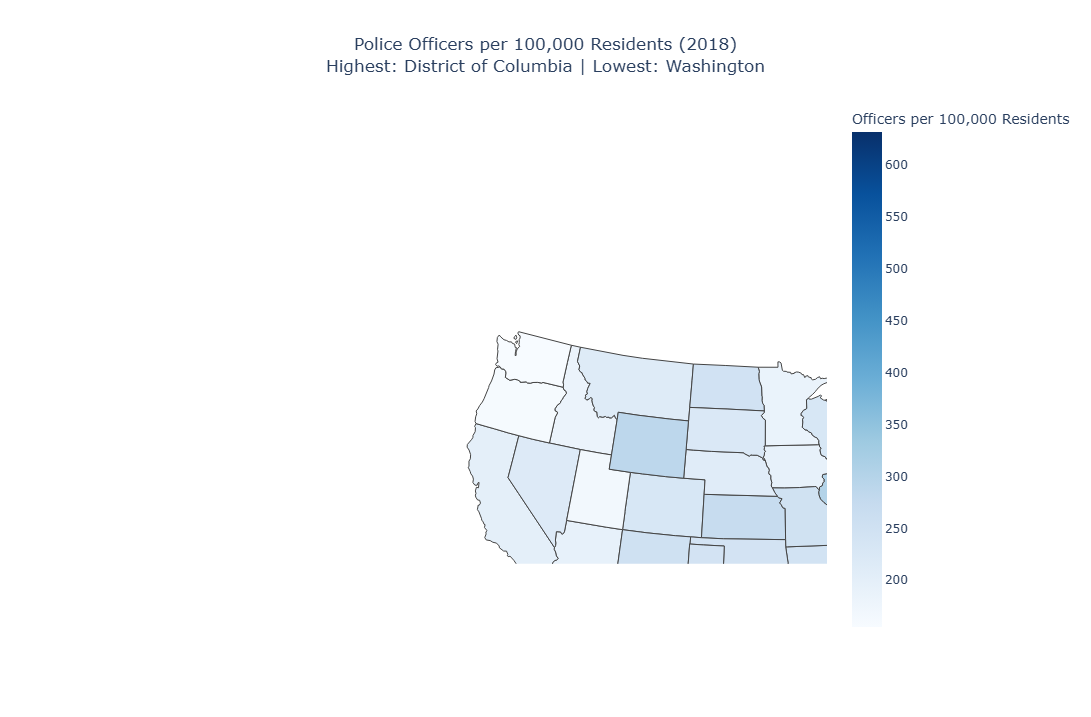

In [14]:
# Task 2
# YOUR CODE HERE

# Load your GeoJSON
# with open('your_file.geojson', 'r') as file:
#     my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
# print(my_geojson['features'][0]['properties'])


import pandas as pd
import plotly.express as px
import zipfile
import json
import os

os.makedirs("bjs_data", exist_ok=True)

with zipfile.ZipFile("download.zip", "r") as zip_file:
    zip_file.extractall("bjs_data")

police_data = pd.read_csv(
    "bjs_data/csllea18stt03.csv",
    skiprows=12,
    encoding="utf-8-sig"
)

police_data = police_data[
    ["State", "Sworn", "Sworn per 100,000 residents"]
].copy()

police_data.columns = [
    "state",
    "sworn_officers",
    "officers_per_100k"
]

police_data["state"] = police_data["state"].str.strip()

police_data["sworn_officers"] = pd.to_numeric(
    police_data["sworn_officers"].astype(str).str.replace(",", ""),
    errors="coerce"
)

police_data["officers_per_100k"] = pd.to_numeric(
    police_data["officers_per_100k"],
    errors="coerce"
)

police_data = police_data.dropna(
    subset=["state", "sworn_officers", "officers_per_100k"]
)

with open("us-states.json", "r", encoding="utf-8") as file:
    my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
print(my_geojson['features'][0]['properties'])

highest_state = police_data.loc[
    police_data["officers_per_100k"].idxmax()
]

lowest_state = police_data.loc[
    police_data["officers_per_100k"].idxmin()
]

fig = px.choropleth(
    police_data,
    geojson=my_geojson,
    locations="state",
    featureidkey="properties.name",
    color="officers_per_100k",
    hover_name="state",
    hover_data={
        "sworn_officers": ":,",
        "officers_per_100k": ":.1f"
    },
    color_continuous_scale="Blues",
    scope="usa",
    title=f"Police Officers per 100,000 Residents (2018)<br>Highest: {highest_state['state']} | Lowest: {lowest_state['state']}"
)

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    width=1100,
    height=700,
    title_x=0.5,
    coloraxis_colorbar_title="Officers per 100,000 Residents"
)

fig.show()